# T2 2D Slices & Masks: Data Augmentation Analysis & Visualization

In this notebook, we test and inspect the data augmentation pipeline on 2D T2 MRI slices and their corresponding tumor masks.

We visualize:
1. **Train Transforms (4x4 grid):** Images and masks passing through geometric (rotation, affine, flip) and intensity/contrast/noise transformations.
2. **Validation Transforms (4x4 grid):** Deterministic preprocessing on the test split.
3. **Single Slice Augmentation Variations (4x4 grid):** Multiple stochastic passes of the same slice to observe augmentation diversity.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

SCRIPT_DIR = Path.cwd()
PARENT = SCRIPT_DIR.parent
sys.path.append(str(SCRIPT_DIR))
sys.path.append(str(PARENT))

from config import config
from dataset import build_dataset, T2Conv2DDataset
import transform

print("Config name:", config.name)
print("Transform config:", config.transform)

Config name: base_transform
Transform config: rnd_h_flip_p=0.5 rnd_rot_deg=10.0 rnd_aff_p=0.5 rnd_down_scale=0.05 rnd_up_scale=0.05 translate_down=5.0 translate_up=5.0 intensity_scale_p=0.2 intensity_scale_factor=0.1 shift_intensity_p=0.3 shift_intensity_offsets=0.1 adjust_contrast_p=0.3 adjust_contrast_gamma=(0.8, 1.25) gaussian_noise_p=0.2 gaussian_noise_mean=0.0 gaussian_noise_std=0.03 gaussian_smooth_p=0.2 gaussian_smooth_sigma_x=(0.25, 0.75) gaussian_smooth_sigma_y=(0.25, 0.75) bias_field_p=0.0 bias_field_coeff_range=(0.0, 0.05) bias_field_degree=3


In [2]:
# Build train and validation datasets with transforms
train_dataset, val_dataset = build_dataset(
    manifest_path=config.manifest_path,
    test_split_ratio=0.2,
    train_transform=transform.train_transform,
    test_transform=transform.val_transforms,
    seed=config.seed
)

# Baseline untransformed datasets to identify slices containing tumor masks
raw_train_dataset = T2Conv2DDataset(
    manifest_path=config.manifest_path,
    transform=None,
    manifest=train_dataset.manifest
)
raw_val_dataset = T2Conv2DDataset(
    manifest_path=config.manifest_path,
    transform=None,
    manifest=val_dataset.manifest
)

print(f"Total train slices: {len(train_dataset)}")
print(f"Total val slices:   {len(val_dataset)}")

Total train slices: 2550
Total val slices:   629


In [3]:
def plot_4x4_grid(dataset, indices, title):
    """Plots a 4x4 grid showing MRI slices with their tumor mask overlaid in transparent color."""
    fig, axes = plt.subplots(4, 4, figsize=(15, 15))
    fig.suptitle(title, fontsize=16, y=1.01)

    for ax, idx in zip(axes.flatten(), indices):
        sample = dataset[idx]
        img = sample.image.squeeze().cpu().numpy()
        mask = sample.mask.squeeze().cpu().numpy()

        # Grayscale background image
        ax.imshow(img, cmap="gray")

        # Overlay tumor mask
        if mask.sum() > 0:
            masked_roi = np.ma.masked_where(mask <= 0.5, mask)
            ax.imshow(masked_roi, cmap="autumn", alpha=0.5, interpolation="none")
            mask_status = f"Mask px: {int(mask.sum())}"
        else:
            mask_status = "No mask"

        ax.set_title(f"ID: {sample.sample_id[:8]} | {mask_status}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## 1. Train Transforms (4x4 Grid)
Below are 16 different train samples passing through `train_transform`. Notice how the mask and anatomical contours stay aligned across flips, rotations, and affine warping, while intensity scaling and noise are applied to the MR image.

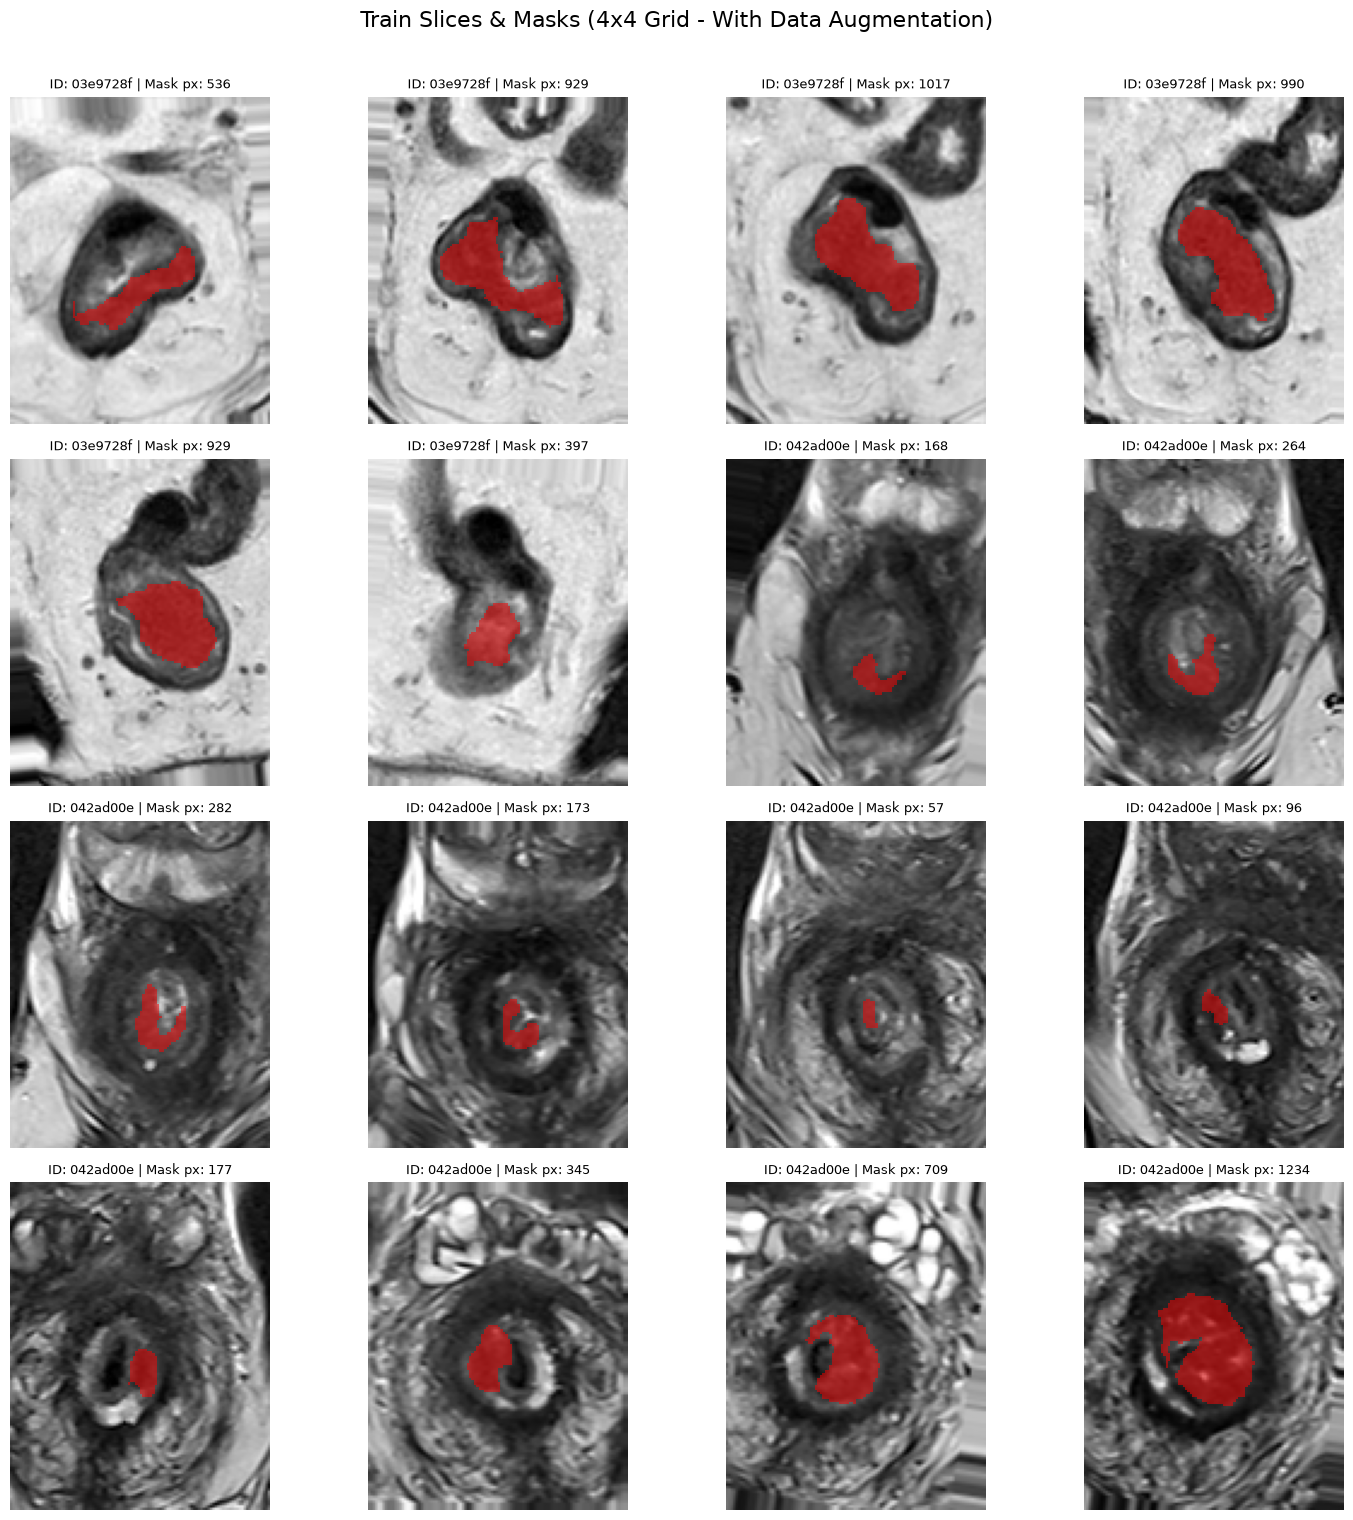

In [4]:
# Select 16 slices that have positive tumor masks
train_pos_indices = [i for i in range(len(raw_train_dataset)) if raw_train_dataset[i].mask.sum() > 0][:16]

plot_4x4_grid(train_dataset, train_pos_indices, "Train Slices & Masks (4x4 Grid - With Data Augmentation)")

## 2. Validation Transforms (4x4 Grid)
Below are 16 validation samples passing through `val_transforms`. Validation uses deterministic processing (channel dimension check and typing) with no stochastic augmentations.

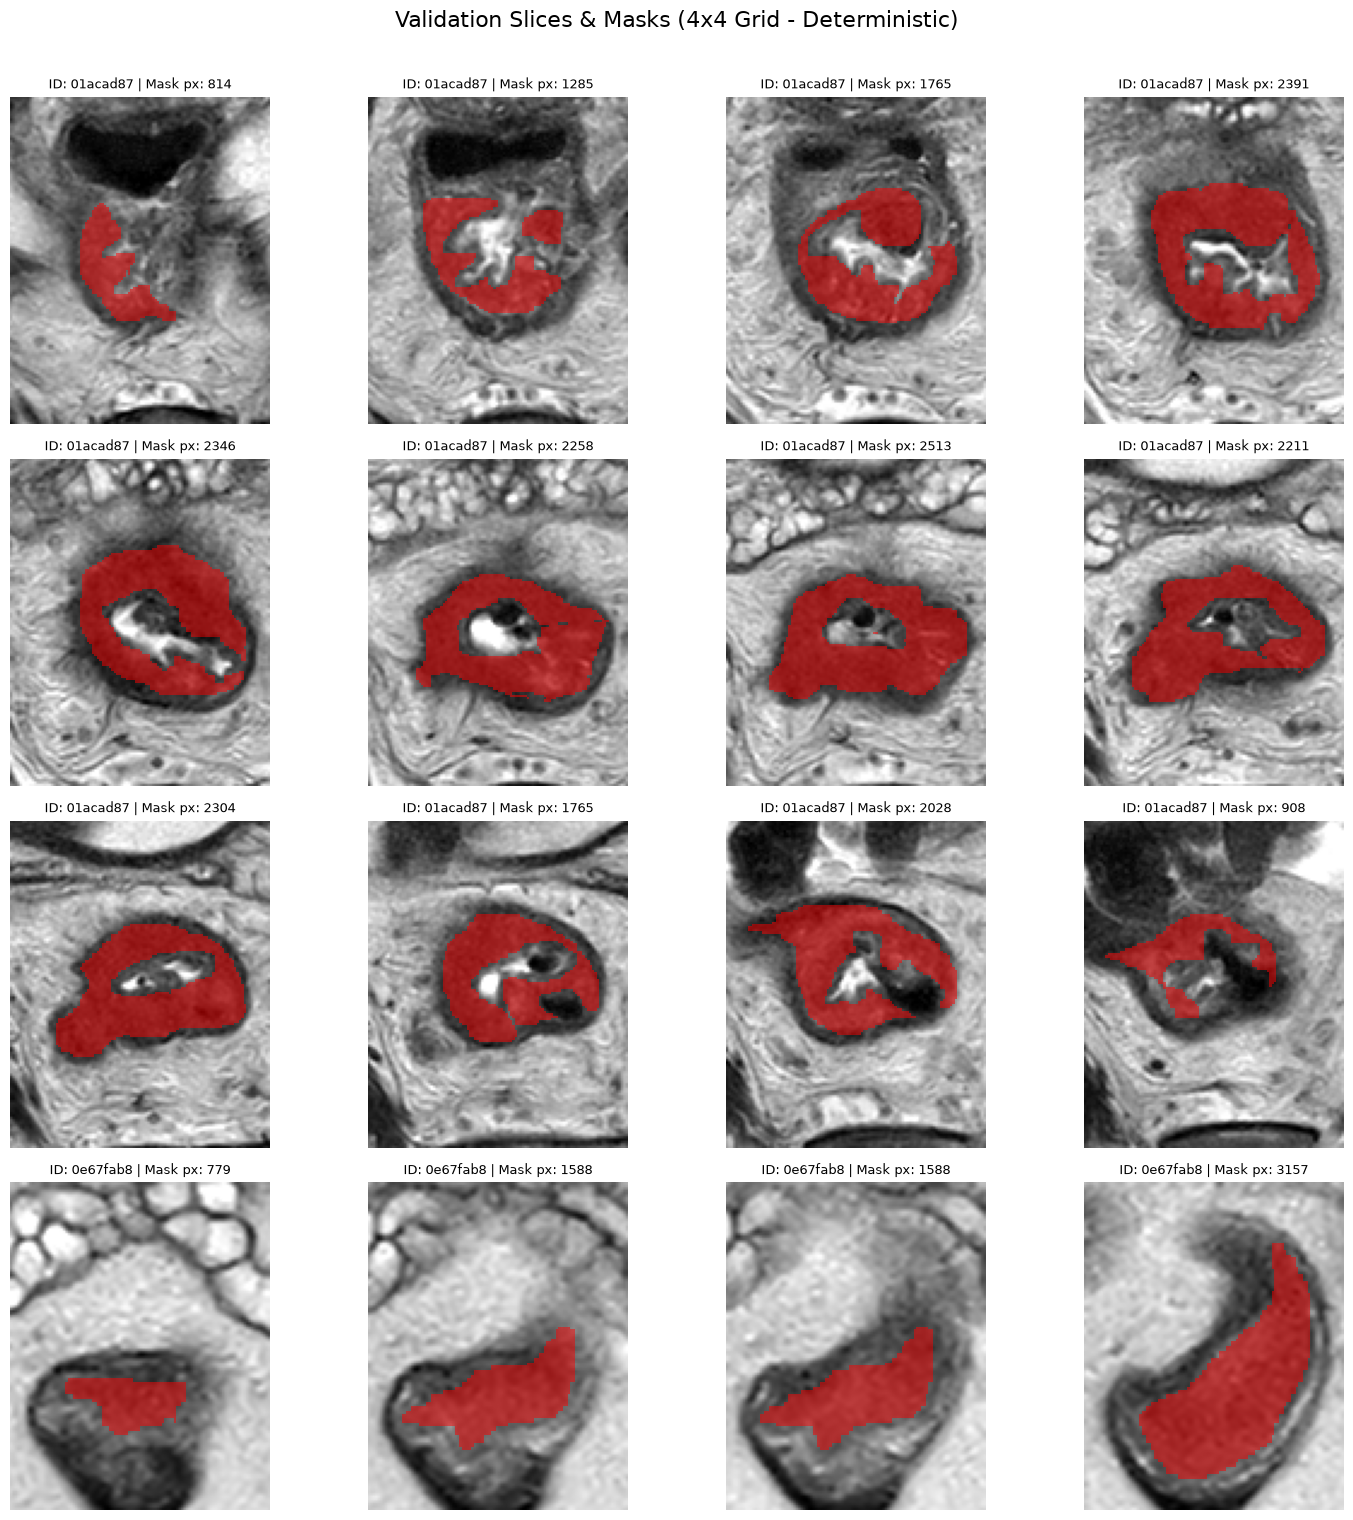

In [5]:
# Select 16 validation slices that have positive tumor masks
val_pos_indices = [i for i in range(len(raw_val_dataset)) if raw_val_dataset[i].mask.sum() > 0][:16]

plot_4x4_grid(val_dataset, val_pos_indices, "Validation Slices & Masks (4x4 Grid - Deterministic)")

## 3. Augmentation Diversity on a Single Slice (4x4 Grid)
To see how a single slice is perturbed across 16 different training iterations, we apply `train_transform` 16 times to the exact same input slice.

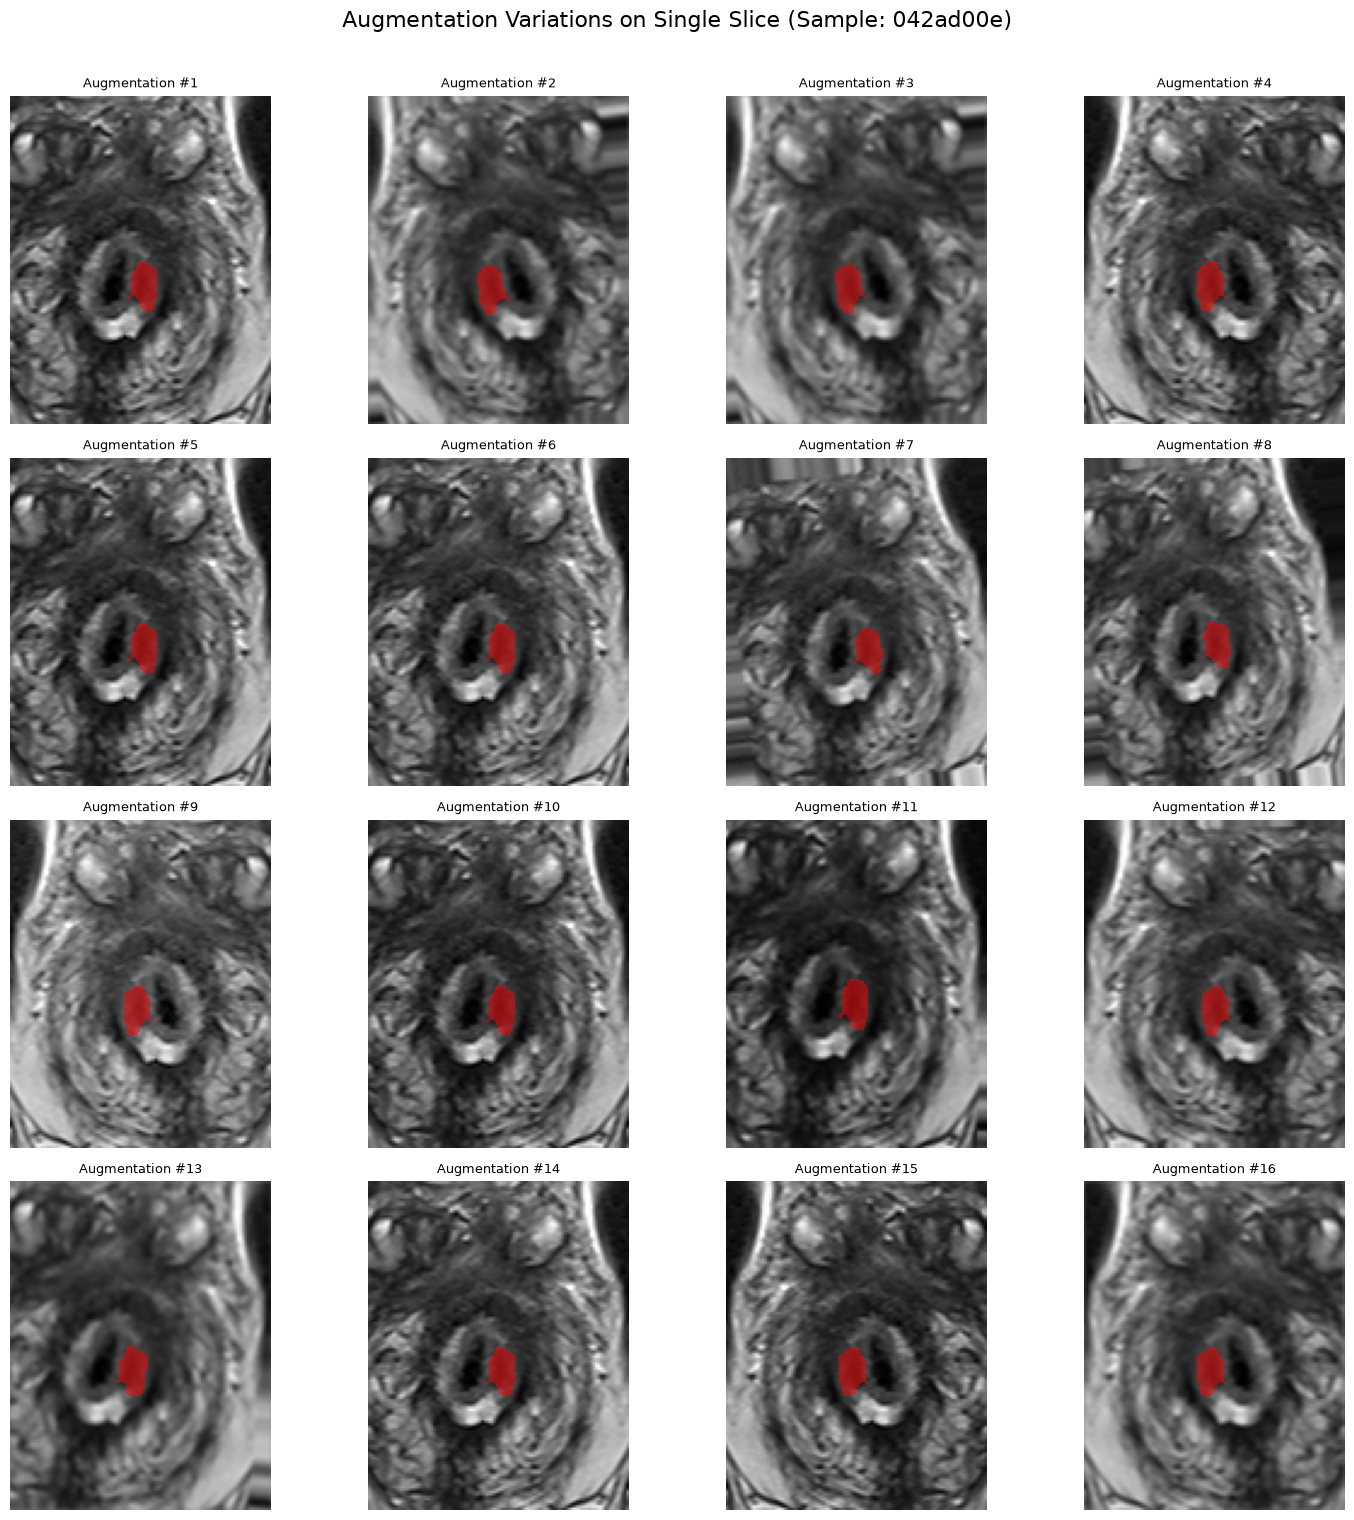

In [6]:
sample_idx = train_pos_indices[12]
raw_sample = raw_train_dataset[sample_idx]

fig, axes = plt.subplots(4, 4, figsize=(15, 15))
fig.suptitle(f"Augmentation Variations on Single Slice (Sample: {raw_sample.sample_id[:8]})", fontsize=16, y=1.01)

for i, ax in enumerate(axes.flatten()):
    img_t, mask_t = transform.train_transform(raw_sample.image, raw_sample.mask)
    img_np = img_t.squeeze().cpu().numpy()
    mask_np = mask_t.squeeze().cpu().numpy()

    ax.imshow(img_np, cmap="gray")
    if mask_np.sum() > 0:
        masked_roi = np.ma.masked_where(mask_np <= 0.5, mask_np)
        ax.imshow(masked_roi, cmap="autumn", alpha=0.5, interpolation="none")

    ax.set_title(f"Augmentation #{i+1}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()